Steady, incompressible flow of a uniform stream $U_\infty$ over a flat plate gives, after the similarity transformation $\eta = y\sqrt{U_\infty/(\nu x)}$ and $u/U_\infty = f'(\eta)$, the Blasius equation

$$f''' + \frac{1}{2}\,f\,f'' = 0, \qquad 0 < \eta < \infty \tag{1}$$

with boundary conditions

$$f(0) = 0, \qquad f'(0) = 0 \ \text{(no slip, no suction)}, \qquad f'(\eta) \to 1 \ \text{as } \eta \to \infty \ \text{(free stream)} \tag{2}$$

This is a boundary value problem, since two conditions are given at $\eta = 0$ and one at $\eta = \infty$. It is solved here with the **shooting method**, using RK3 and RK4 for the initial value problems. The result is checked against the known value $f''(0) \approx 0.332$.

In [4]:
import numpy as np

y=np.array([0,0,0.332])
print(y[0],y[1],y[2])

0.0 0.0 0.332


In [5]:
def G(y):
    # your three derivatives go here
    return np.array([y[1] ,y[2], -1/2*(y[0]*y[2])])

y=np.array([1,2,3])
print(G(y))

[ 2.   3.  -1.5]


In [6]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + (h/2)*k1)
    k3 = G(Y - (h*k1) + 2*h*k2)
    Y_new = Y + (h/6)*(k1 + 4*k2 + k3)
    return Y_new

Y0 = np.array([0, 0, 0.332])
print(rk3_step(Y0, 0.1))

[0.00166    0.0332     0.33199081]


In [7]:
def residual(s, h, eta_inf):
    Y = np.array([0, 0, s])      # f(0)=0, f'(0)=0, f''(0)=s
    n = round(eta_inf / h)
    for i in range(n):
        Y = rk3_step(Y, h)       # one RK3 step
    return Y[1] - 1              # f'(eta_inf) - 1


print(residual(0.3, 0.1, 10))
print(residual(0.332, 0.1, 10))
print(residual(0.4, 0.1, 10))

-0.0654423962078492
-0.00011350507788987496
0.13213651172221774


In [31]:
def bisection(h, eta_inf, a=0.3, b=0.4, tol=1e-12):
    Fa = residual(a, h, eta_inf)
    while (b - a) > tol:
        m = (a + b) / 2
        Fm = residual(m, h, eta_inf)
        if Fa * Fm < 0:
            b = m
        else:
            a = m
            Fa = Fm
    return (a + b) / 2

s = bisection(0.1, 16)
print(s)

0.33205653243821875


In [32]:
h_list = [0.4, 0.2, 0.1, 0.05, 0.025]
s_list = []
for h in h_list:
    s_list.append(bisection(h, 16))
    print(h, s_list[-1])

0.4 0.33197714477100804
0.2 0.3320495975061931
0.1 0.33205653243821875
0.05 0.3320572466062003
0.025 0.3320573257125943


In [50]:
s_ref = 0.332057336215196
err = np.abs(np.array(s_list) - s_ref)
print(err)

[8.01914442e-05 7.73870900e-06 8.03776977e-07 8.96089957e-08
 1.05026017e-08]


In [51]:
order = []
for i in range(len(err) - 1):
    order.append(np.log2(err[i] / err[i+1]))
print([round(float(p), 2) for p in order])

[3.37, 3.27, 3.17, 3.09]


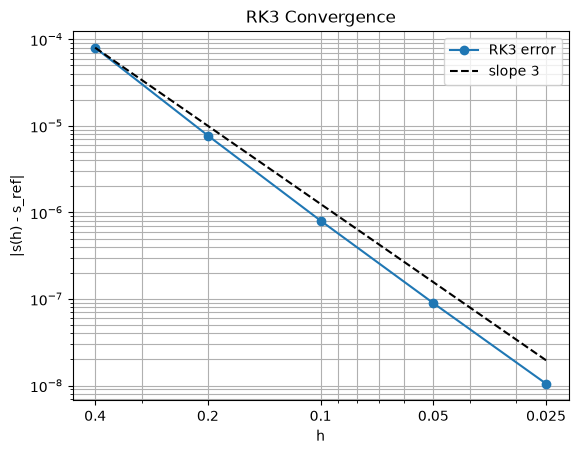

In [65]:
import matplotlib.pyplot as plt

plt.loglog(h_list, err, "o-", label="RK3 error")
plt.loglog(hh, err[0]*(hh/hh[0])**3, "k--", label="slope 3")
plt.gca().invert_xaxis()
plt.xticks(h_list, [str(h) for h in h_list])
plt.gca().xaxis.set_minor_formatter(plt.NullFormatter())
plt.xlabel("h")
plt.ylabel("|s(h) - s_ref|")
plt.title("RK3 Convergence")
plt.grid(True, which="both")
plt.legend()
plt.show()

In [53]:
def solve_rk3(s, h, eta_inf):
    n = round(eta_inf / h)
    Y = np.array([0, 0, s])
    Y_all = [Y]                      # starting values go in first
    for i in range(n):
        Y = rk3_step(Y, h)
        Y_all.append(Y)
    return np.array(Y_all)           # shape (n+1, 3)

In [54]:
h = 0.025
eta_inf = 16
sol = solve_rk3(s_list[-1], h, eta_inf)
eta = h * np.arange(len(sol))

print(sol.shape)
print(sol[0])
print(sol[-1])

(641, 3)
[0.         0.         0.33205733]
[1.42792125e+01 1.00000000e+00 1.69289308e-23]


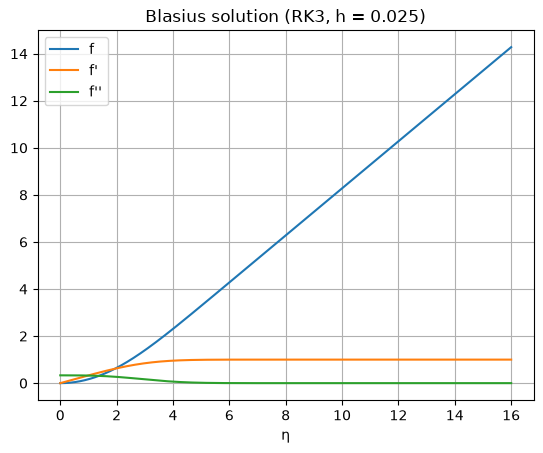

In [55]:
plt.plot(eta, sol[:, 0], label="f")
plt.plot(eta, sol[:, 1], label="f'")
plt.plot(eta, sol[:, 2], label="f''")
plt.xlabel("η")
plt.title("Blasius solution (RK3, h = 0.025)")
plt.grid(True)
plt.legend()
plt.show()

Here in the plot f′ rises monotonically from 0 at the wall to 1 in the free stream, reaching 0.99 near η ≈ 5, which gives the boundary layer thickness. f″(0) = 0.332 gives the wall shear stress.

In [56]:
def rk4_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + (h/2)*k1)
    k3 = G(Y + (h/2)*k2)
    k4 = G(Y + h*k3)
    Y_new = Y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    return Y_new

Y0 = np.array([0, 0, 0.332])
print(rk4_step(Y0, 0.1))

[0.00166    0.03319977 0.33199081]


In [57]:
def residual(s, h, eta_inf, step=rk3_step):
    Y = np.array([0, 0, s])
    n = round(eta_inf / h)
    for i in range(n):
        Y = step(Y, h)
    return Y[1] - 1

print(residual(0.3, 0.1, 10))
print(residual(0.332, 0.1, 10))
print(residual(0.4, 0.1, 10))

-0.0654423962078492
-0.00011350507788987496
0.13213651172221774


In [58]:
def bisection(h, eta_inf, a=0.3, b=0.4, tol=1e-10, step=rk3_step):
    Fa = residual(a, h, eta_inf, step)
    while (b - a) > tol:
        m = (a + b) / 2
        Fm = residual(m, h, eta_inf, step)
        if Fa * Fm < 0:
            b = m
        else:
            a = m
            Fa = Fm
    return (a + b) / 2

print(bisection(0.1, 10, step=rk4_step))

0.3320573456119746


In [59]:
h_list = [0.4, 0.2, 0.1, 0.05, 0.025]
s_list4 = []
for h in h_list:
    s_list4.append(bisection(h, 10, step=rk4_step))
    print(h, s_list4[-1])

s_ref = 0.332057336
err4 = np.abs(np.array(s_list4) - s_ref)
print(err4)

0.4 0.33205881579779084
0.2 0.33205745746381576
0.1 0.3320573456119746
0.05 0.33205733778886487
0.025 0.33205733723007136
[1.47979779e-06 1.21463816e-07 9.61197461e-09 1.78886489e-09
 1.23007138e-09]


### Choice of $\eta_\infty$

The boundary condition $f'(\infty) = 1$ cannot be applied at infinity on a computer, so it is applied at a large but finite value $\eta_\infty$.

- Far from the wall, $f''$ decays very fast towards zero. At $\eta_\infty = 10$, $f''$ is still about $8\times10^{-9}$, so $f'$ has not quite reached 1.
- The root-finder then raises $s = f''(0)$ slightly (by about $10^{-9}$) to force $f'(\eta_\infty) = 1$. This shift is the same for every step size $\Delta\eta$, so it does not shrink when $\Delta\eta$ is reduced.
- When the errors of RK4 fall to about $10^{-9}$, this fixed shift becomes larger than the method's own error, and the observed order drops below 4.
- Taking $\eta_\infty = 16$ makes $f''(\eta_\infty)$ negligible, so the shift is far below the errors being measured. It also divides exactly by every step size used ($0.4,\ 0.2,\ 0.1,\ 0.05,\ 0.025$), giving a whole number of steps each time.

For $\eta_\infty = 16$ the truncation effect no longer hides the truncation error of the Runge-Kutta method, and the convergence study shows the expected order.

In [60]:
h_list = [0.4, 0.2, 0.1, 0.05, 0.025]
s_ref = 0.332057336215196

s_list4b = []
for h in h_list:
    s_list4b.append(bisection(h, 16, tol=1e-12, step=rk4_step))
    print(h, s_list4b[-1])

err4b = np.abs(np.array(s_list4b) - s_ref)
print(err4b)

order4b = []
for i in range(len(err4b) - 1):
    order4b.append(np.log2(err4b[i] / err4b[i+1]))
print([round(float(p), 2) for p in order4b])

0.4 0.3320588129132376
0.2 0.3320574564208073
0.1 0.3320573446198978
0.05 0.33205733676841187
0.025 0.3320573362503637
[1.47669804e-06 1.20205611e-07 8.40470177e-09 5.53215862e-10
 3.51677021e-11]
[3.62, 3.84, 3.93, 3.98]


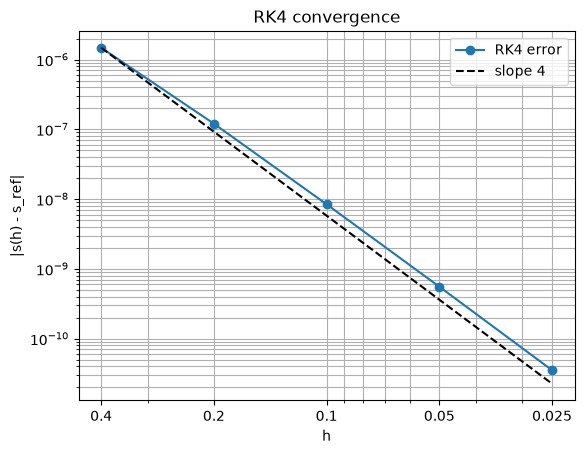

In [61]:
import matplotlib.pyplot as plt

hh = np.array(h_list)
plt.loglog(hh, err4b, "o-", label="RK4 error")
plt.loglog(hh, err4b[0]*(hh/hh[0])**4, "k--", label="slope 4")
plt.gca().invert_xaxis()
plt.xticks(h_list, [str(h) for h in h_list])
plt.gca().xaxis.set_minor_formatter(plt.NullFormatter())
plt.xlabel("h")
plt.ylabel("|s(h) - s_ref|")
plt.title("RK4 convergence")
plt.grid(True, which="both")
plt.legend()
plt.show()

In [62]:
def solve_rk4(s, h, eta_inf, step=rk4_step):
    n = round(eta_inf / h)
    Y = np.array([0, 0, s])
    Y_all = [Y]
    for i in range(n):
        Y = step(Y, h)
        Y_all.append(Y)
    return np.array(Y_all)

In [63]:
h = 0.025
eta_inf = 16
sol4 = solve_rk4(s_list4b[-1], h, eta_inf)
eta4 = h * np.arange(len(sol4))

print(sol4.shape)
print(sol4[0])
print(sol4[-1])

(641, 3)
[0.         0.         0.33205734]
[1.42792123e+01 1.00000000e+00 1.70241072e-23]


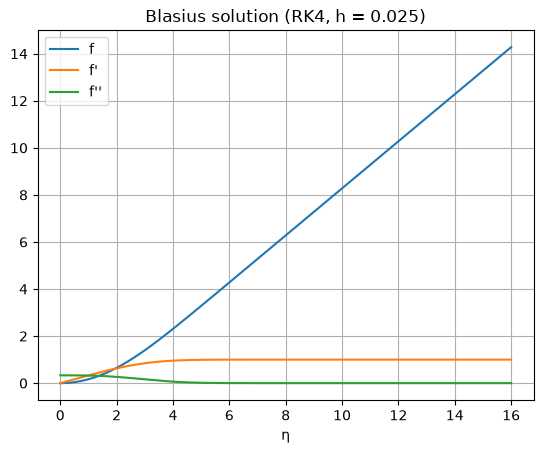

In [64]:
plt.plot(eta4, sol4[:, 0], label="f")
plt.plot(eta4, sol4[:, 1], label="f'")
plt.plot(eta4, sol4[:, 2], label="f''")
plt.xlabel("η")
plt.title("Blasius solution (RK4, h = 0.025)")
plt.grid(True)
plt.legend()
plt.show()